# اختبار برمجيات JPEG فقط — ليس كاشف وجوه
الافتراضي QUICK: أشكال هندسية للتأكد من التدريب والحفظ والاستكمال والمقارنة. لا تستخدم درجاته أو أوزانه لكشف أصالة وجوه. الواجهة تسمح بمعاينة JPEG دون أحكام أصالة. لتدريب الوجوه استخدم FaceJPEG_Real_CPU_Ready.ipynb الذي يبدأ بـREAL_CPU ويتطلب بيانات وجوه فعلية.

## 1 — تهيئة الكود وفحص بيئة التشغيل وGPU
تكتب هذه الخلية الكود المضمن في مجلد إصدار مستقل، وتحافظ على أي تغييرات محلية. ثم تفحص Torch/Torchvision وCUDA واسم البطاقة وذاكرتها. `+cpu` يصف بناء PyTorch؛ و`GPU=False` وحده لا يثبت سبب بطء جلسة سابقة. عند تغيير إصدار المشروع استخدم مجلدًا جديدًا بدل الكتابة فوق تعديلاتك.

In [1]:
import os, sys, json, gzip, base64, hashlib, importlib.util, subprocess, time
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
_blob = base64.b64decode('...')
assert hashlib.sha256(_blob).hexdigest() == '791c3e29b2c8f25fca9e77724d3bf80b025b29fb34a2ea38fb1e70936724a1cf', "Embedded source checksum failed"
_files = json.loads(gzip.decompress(_blob).decode("utf-8"))
_base = Path(os.environ.get("FACEJPEG_WORKSPACE", "/content" if IN_COLAB else str(Path.cwd())))
PROJECT = (_base / "facejpeg_final_v2_3_1").resolve()
PROJECT.mkdir(parents=True, exist_ok=True)
for _rel, _text in _files.items():
    _path = (PROJECT / _rel).resolve()
    if not _path.is_relative_to(PROJECT):
        raise ValueError("Unsafe source path")
    if _path.exists() and _path.read_text(encoding="utf-8") != _text:
        raise FileExistsError(f"{_path} has local changes: choose a new FACEJPEG_WORKSPACE or retain those changes")
    _path.parent.mkdir(parents=True, exist_ok=True)
    _path.write_text(_text, encoding="utf-8")
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT)) if str(PROJECT) not in sys.path else None
def _refresh_project_imports():
    # Reload only this project's modules if an earlier notebook used another folder.
    removed = []
    for _name, _module in list(sys.modules.items()):
        if _name == "facejpeg" or _name.startswith("facejpeg.") or _name in {"app", "scripts.make_demo", "scripts.download_data"}:
            _file = getattr(_module, "__file__", None)
            if not _file or not Path(_file).resolve().is_relative_to(PROJECT):
                sys.modules.pop(_name, None)
                removed.append(_name)
    return removed
_removed = _refresh_project_imports()
if _removed:
    print("أعيد تهيئة وحدات المشروع من النسخة الجديدة:", len(_removed))
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT / ".cache/matplotlib"))
_torch_pair_ok = False
try:
    import torch, torchvision
    _torch_pair_ok = True
    print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__)
    print("CUDA build:", torch.version.cuda, "GPU available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        _free, _total = torch.cuda.mem_get_info()
        print("GPU:", torch.cuda.get_device_name(), "free/total GiB:", round(_free/2**30,2), round(_total/2**30,2))
    else:
        print("لا توجد CUDA متاحة؛ يمكن تدريب الوجوه بوضع REAL_CPU. QUICK اختبار أشكال فقط، وREAL يحتاج GPU.")
except ImportError:
    print("Torch/Torchvision غير مثبتين؛ ستُعرض تعليمات التثبيت في المرحلة2.")
except Exception as _error:
    print("فشل استيراد زوج Torch/Torchvision:", type(_error).__name__)
print("Project:", PROJECT)

PyTorch: 2.5.1+cpu Torchvision: 0.20.1+cpu
CUDA build: None GPU available: False
لا توجد CUDA متاحة؛ يمكن تدريب الوجوه بوضع REAL_CPU. QUICK اختبار أشكال فقط، وREAL يحتاج GPU.
Project: /workspace/Final-Projects/facejpeg_final_v2_3_1


## 2 — تثبيت المكتبات مع الحفاظ على CUDA
في Colab نحافظ على زوج Torch/Torchvision المثبت بدل إعادة تثبيته بعجلة CPU. تُثبت بقية المكتبات بنطاقات متوافقة وتظهر رسائل pip مع نبضة كل15 ثانية أثناء الانتظار. لا تعني النبضة أن التنزيل تقدم؛ راجع آخر سطر pip. عند خطأ استيراد زوج Torch، ابدأ جلسة Colab نظيفة مع GPU؛ لا تُعطّل التحقق من TLS. محليًا يُستخدم requirements.txt إذا كان Torch غائبًا.

In [2]:
import threading
if IN_COLAB and not _torch_pair_ok:
    raise RuntimeError("ابدأ جلسة Colab نظيفة مع CPU أو GPU حسب النمط وأعد التشغيل؛ لن نستبدل زوج Torch المعطوب تلقائيًا.")
if _torch_pair_ok:
    import re
    _torch_version = tuple(map(int, re.match(r"([0-9]+)[.]([0-9]+)", str(torch.__version__)).groups()))
    if not (2,5) <= _torch_version < (3,0):
        raise RuntimeError("يلزم Torch >=2.5 و<3 مع Torchvision المتوافق؛ اختر إصدارًا مدعومًا من تعليمات PyTorch الرسمية أو جلسة Colab حديثة.")
_req = "requirements-colab.txt" if _torch_pair_ok else "requirements.txt"
_done = threading.Event()
_install_start = time.monotonic()
def _install_heartbeat():
    while not _done.wait(15):
        print(f"[تثبيت المتطلبات] ما زالت عملية pip تعمل؛ elapsed={time.monotonic()-_install_start:.0f}s — راجع آخر عملية تنزيل أعلاه", flush=True)
_thread = threading.Thread(target=_install_heartbeat, daemon=True)
_thread.start()
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", _req], check=True)
finally:
    _done.set(); _thread.join(timeout=1)
import torch, torchvision
from facejpeg.runtime import hardware_info
from IPython.display import display, Markdown, Image as DisplayImage
print(json.dumps(hardware_info(), ensure_ascii=False, indent=2))
print(f"انتهى التثبيت والتحقق خلال {time.monotonic()-_install_start:.1f}s")

{
  "torch": "2.5.1+cpu",
  "cuda_build": null,
  "cuda_available": false,
  "cpu_count": 5,
  "guidance_ar": "لا توجد CUDA متاحة. اختر REAL_CPU لتدريب الوجوه على المعالج، أو QUICK لاختبار البرمجيات فقط. لوضع REAL الذي يضبط الشبكة اختر Runtime → Change runtime type → GPU. نسخة torch ذات اللاحقة +cpu لا تستخدم CUDA. هذا التشخيص لا يثبت سبب انتظار جلسة سابقة."
}
انتهى التثبيت والتحقق خلال 0.5s


## 3 — الإعدادات ومصدر البيانات والحفظ
الافتراضي REAL_CPU لتدريب الوجوه بلا GPU، وREAL لضبط آخر طبقات الشبكة على GPU. اختبار QUICK له دفتر منفصل. اختر المصدر kaggle أو ZIP أو Drive. ضع ZIP البيانات في لوحة Files واكتب مساره في DATA_ZIP، أو جهّز مجلد real وfake على Drive. اترك USE_DRIVE=False إذا تعذرت مصادقته، ونزّل النتائج لاحقًا من المرحلة9.

JPEG_PROBABILITY=0.5 يعني أن كل زيارة لصورة تدريب تختار نسخة JPEG باحتمال50%، وتختار جودة عشوائية بالتساوي من القائمة. البقية تستخدم الأصل؛ القلب الأفقي له السياسة نفسها في A وB. على CPU تُستخرج ميزات الأصل والنسخ المضغوطة مرة واحدة ثم تُختار عشوائيًا كل حقبة. تغيير جودة الواجهة وحده لا يغيّر التدريب.

في REAL_CPU الحد20 حقبة وحتى1000 صورة لكل فئة بعد التدقيق والتقسيم. هذه عينة ابتدائية لا ضمان دقة. اختر اسم EXPERIMENT جديدًا عند تغيير أي إعداد أو البيانات؛ تُقفل خطة المقارنة لمنع تعديلها بناء على الاختبار. يبدأ الحفظ المؤقت في RUN؛ لا يغني حفظ الدفتر عن حفظ الأوزان.

In [3]:
BEST = None
CHECKPOINTS = {}
TRAINING_READY = False
DATA_READY = False
manifest = None
if globals().get("demo") is not None:
    demo.close()
demo = None
ALLOW_SOFTWARE_PREVIEW = True
MODE = "QUICK"  # @param ["QUICK"]
SOURCE = "kaggle"  # @param ["kaggle", "zip", "drive"]
EXPERIMENT = "jpeg_quick_v2_3_1" if MODE == "QUICK" else "jpeg_faces_cpu_v2_3_1" if MODE == "REAL_CPU" else "jpeg_faces_gpu_v2_3_1"
USE_DRIVE = False  # @param {type:"boolean"}
DATA_ZIP = ""  # مثال /content/faces.zip
DRIVE_RAW_PATH = "/content/drive/MyDrive/facejpeg/raw"
METADATA_CSV = None  # اختياري: path,identity,source_id بمسارات نسبية
EPOCHS = 2 if MODE == "QUICK" else 20 if MODE == "REAL_CPU" else 10
BATCH_SIZE = 64 if MODE == "REAL_CPU" else None  # دفعة ميزات، وليست64 صورة للشبكة
WORKERS = 0 if MODE == "REAL_CPU" else None
MAX_PER_CLASS = 1000 if MODE == "REAL_CPU" else None
RESUME = True
ALLOW_CPU_REAL = False  # سماح صريح لتدريب الوجوه البطيء بلا GPU
EXPORT_INCLUDE_PREPARED = False  # ZIP خفيف؛ صور الاستكمال محفوظة في Drive عند تفعيله
SHARE_GRADIO = True  # رابط عام مؤقت عند تشغيل الواجهة في Colab
LAUNCH_UI = os.environ.get("FACEJPEG_NO_UI") != "1"
assert MODE in {"QUICK", "REAL", "REAL_CPU"} and SOURCE in {"kaggle", "zip", "drive"}
QUICK = MODE == "QUICK"
CPU_REAL = MODE == "REAL_CPU"
if MODE == "REAL" and not torch.cuda.is_available() and not ALLOW_CPU_REAL:
    raise RuntimeError("اختر MODE='REAL_CPU' لتدريب الوجوه بلا GPU، أو فعّل GPU لوضع REAL. QUICK اختبار برمجيات فقط.")
if USE_DRIVE or (not QUICK and SOURCE == "drive"):
    if not IN_COLAB:
        raise RuntimeError("محليًا استخدم ZIP/مجلدًا محليًا بدل تركيب Drive")
    from google.colab import drive
    drive.mount("/content/drive")
RUNS_BASE = Path("/content/drive/MyDrive/facejpeg_runs") if USE_DRIVE else PROJECT / "runs"
RUN = RUNS_BASE / EXPERIMENT
PREPARED = RUN / "prepared"
RUN.mkdir(parents=True, exist_ok=True)
print("MODE:", MODE, "data:", "procedural fixture — software test only" if QUICK else SOURCE)
print("RUN:", RUN)
JPEG_TRAIN_QUALITIES = [90, 70, 50, 30]
JPEG_PROBABILITY = 0.5
MODEL_FOR_UI = "jpeg_augmented"  # أو baseline؛ اختيار محدد مسبقًا، لا فائز تلقائيًا

MODE: QUICK data: procedural fixture — software test only
RUN: /workspace/Final-Projects/facejpeg_final_v2_3_1/runs/jpeg_quick_v2_3_1


## 4 — تحميل البيانات وفحصها وتقسيمها
REAL يقترح [140k Real and Fake Faces](https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces): فوتوغرافيات FFHQ ووجوه StyleGAN. نحو4GiB ميزانية تخطيط للتنزيل لا قياسًا تحققنا منه؛ اترك12–20GiB. راجع `docs/DATASET_CARD_AR.md` وشروط المصدر غير التجاري والاعتمادات؛ ترخيص مرآة Kaggle الحالي لم يمكن فحصه بسبب الحجب السابق. لا تتضمن هذه الحزمة بيانات الوجوه.

403 من الوكيل يختلف عن401 للمصادقة و403 لصلاحية المجموعة و404 لعدم وجودها؛ تظهر رسالة تشخيصية ولا نفترض نجاح التنزيل. ZIP/Drive بديلان. الهيكل `raw/real/a.jpg` و`raw/fake/b.png`؛ يقبل تداخل train/valid/test لكنه يعيد تقسيمه بعد التدقيق.

تُفحص كل الصور والتكرارات أولًا. جميع النسخ/الهوية المعروفة تبقى في مجموعة واحدة؛ تقسيم مجموعات طبقي تقريبي70/15/15. تُستبعد تعارضات التصنيف وتُحذف التكرارات المتطابقة. لا يضمن pHash كشف كل النسخ أو فصل الأشخاص بلا metadata. بعد التقسيم تُطبَّق المعالجة نفسها RGB/قص224×224/PNG للفئتين؛ لا تزال بصمات المصدر والضغط السابق قيدًا. يظهر تقدم audit ثم grouping ثم normalization منفصلًا. عند وجود manifest محفوظ يُفحص ويُعاد استعماله دون إعادة تقسيم.

عند تعذر التحميل تظهر رسالة عربية وخطوات ZIP؛ تُتخطى المراحل المعتمدة على البيانات حتى إصلاح المصدر وإعادة المرحلة3 ثم4. لا يُستبدل مصدر الوجوه بعينة أشكال تلقائيًا.

In [4]:
from zipfile import BadZipFile
DATA_READY = False
TRAINING_READY = False
BEST = None
CHECKPOINTS = {}
manifest = None
if globals().get("demo") is not None:
    demo.close()
demo = None
try:
    import pandas as pd
    from facejpeg.data import prepare, safe_extract, validate_manifest
    from scripts.make_demo import make_demo
    from scripts.download_data import download
    _kind = "procedural_fixture" if QUICK else "research_faces"
    if not (PREPARED / "manifest.csv").exists():
        if QUICK:
            RAW_ROOT = PROJECT / "data" / (EXPERIMENT + "_fixture")
            if not RAW_ROOT.exists():
                make_demo(RAW_ROOT, count=20)
        elif SOURCE == "kaggle":
            RAW_ROOT = download(RUN / "download.json")
        elif SOURCE == "zip":
            if not DATA_ZIP or not Path(DATA_ZIP).is_file():
                raise FileNotFoundError("ارفع ZIP البيانات من أيقونة الملفات في Colab ثم اكتب مساره في DATA_ZIP بالمرحلة3.")
            RAW_ROOT = safe_extract(DATA_ZIP, PROJECT / "data" / (EXPERIMENT + "_raw"))
        else:
            RAW_ROOT = Path(DRIVE_RAW_PATH)
        prepare(RAW_ROOT, PREPARED, metadata=METADATA_CSV, data_kind=_kind, max_per_class=MAX_PER_CLASS)
    manifest = validate_manifest(PREPARED)
    audit = json.loads((PREPARED / "audit.json").read_text())
    if audit["data_kind"] != _kind:
        raise ValueError("هذا الاسم مستخدم لبيانات/وضع مختلف. اختر اسم تجربة جديدًا.")
    display(pd.crosstab(manifest.split, manifest.label).rename(columns={0:"فوتوغرافية/رمز0",1:"مولّدة/رمز1"}))
    display(pd.read_csv(PREPARED / "source_format_resolution.csv"))
    print("تم فحص التقسيم: لا تداخل في المجموعات أو الهوية/المصدر المعروفين.")
    DATA_READY = True
except (OSError, ValueError, RuntimeError, BadZipFile) as _data_error:
    print("⚠️ لم تجهز بيانات الوجوه؛ لن يبدأ التدريب أو التقييم أو كشف الأصالة.")
    print("السبب:", str(_data_error))
    print("للمتابعة: ارفع ZIP بيانات به real وfake من لوحة Files، ثم اختر SOURCE='zip' وحدد DATA_ZIP في المرحلة3 وأعد3 ثم4. أو أصلح الوصول إلى Kaggle. لا يوجد انتقال تلقائي إلى QUICK.")


تم فحص التقسيم: لا تداخل في المجموعات أو الهوية/المصدر المعروفين.


label,فوتوغرافية/رمز0,مولّدة/رمز1
split,,
test,3,3
train,14,14
val,3,3


,label,format,count,width_min,width_median,width_max,height_min,height_median,height_max
0,0,PNG,20,224,224.0,224,224,224.0,224
1,1,PNG,20,224,224.0,224,224,224.0,224


## 5 — بناء MobileNetV3-Small
نفحص البنية ورأسًا ثنائيًا (real=0, fake=1). أوزان ImageNet الرسمية تُحمّل مع فحص التجزئة في المرحلة6. REAL_CPU يثبت ميزات ImageNet ويدرّب الرأس على الوجوه، وREAL يضبط آخر3 كتل. الأوزان الهندسية لا تفعّل الكشف.

In [5]:
from facejpeg.common import build_model
_probe = build_model(pretrained=False)
print("Architecture: MobileNetV3-Small; outputs:", _probe.classifier[-1].out_features)
print("Parameters:", sum(p.numel() for p in _probe.parameters()))
del _probe

Architecture: MobileNetV3-Small; outputs: 1
Parameters: 1518881


## 6 — تدريب A وB وتثبيتهما قبل الاختبار
يُدرّب A أولًا ثم B على manifest نفسه والبذرة وإعدادات التدريب نفسها. B فقط تضيف JPEG. لا تُضغط صور التحقق أثناء التدريب، ولا تُستخدم صور الاختبار لاستخراج الميزات. كل نسخة تدريب مضغوطة مستقلة من الأصل الموحد224×224.

على CPU قد يستغرق استخراج ميزات B وقتًا أطول لأنه يحسب أربع جودات وقلبها الأفقي؛ لا يعيد الشبكة في كل حقبة. التوقف المبكر واختيار best.pt وحدود القرار من التحقق فقط. comparison_plan.json يحفظ الخطة، وmodels_locked.json يسجل بصمتي النموذجين وحدودهما قبل أي تقييم اختبار. إعادة الخلية بعد اكتمالها تعيد استخدام النموذجين المثبتين. بعد انقطاع جزئي يُستكمل التدريب بنفس الإعدادات.

Training: baseline
Training: jpeg_augmented
النموذجان مثبتان، ولم نفتح الاختبار بعد.


,epoch,train_loss,val_loss,train_accuracy_at_0_5,val_accuracy_at_0_5,epoch_seconds,train_images_per_second,learning_rate_used,eta_remaining_epochs_seconds,learning_rate_next
0,1,0.509172,0.213357,0.75,1.0,0.010365,2701.491986,0.001,0.010365,0.001
1,2,0.106635,0.153496,1.00,1.0,0.012167,2301.242318,0.001,0.000000,0.001


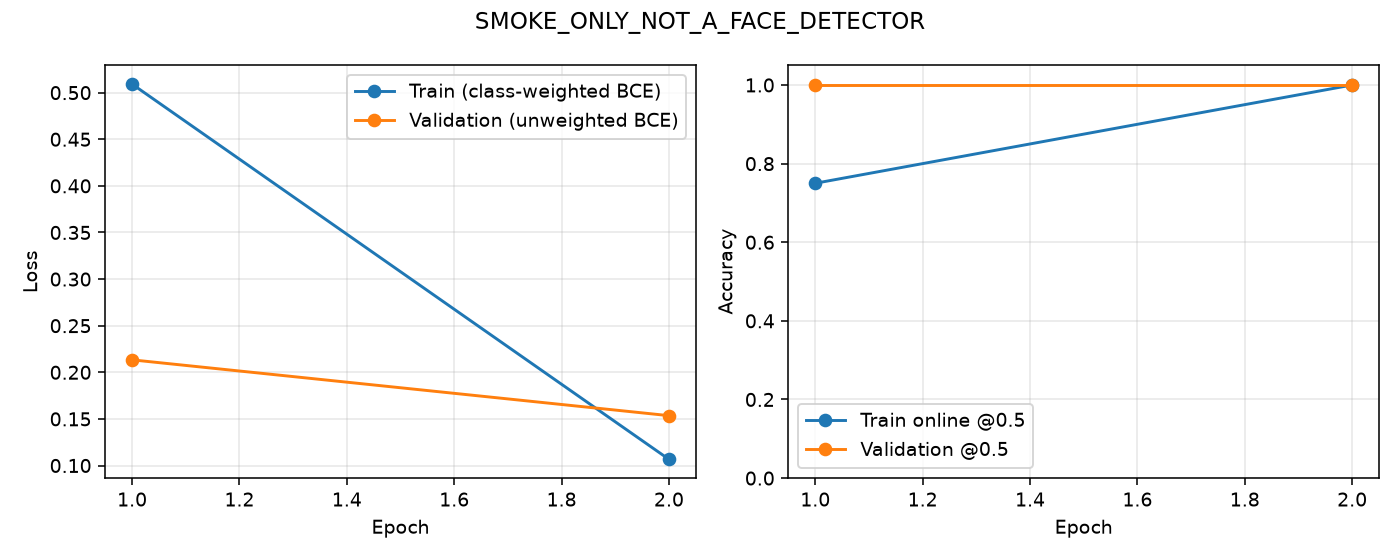

,epoch,train_loss,val_loss,train_accuracy_at_0_5,val_accuracy_at_0_5,epoch_seconds,train_images_per_second,learning_rate_used,eta_remaining_epochs_seconds,learning_rate_next
0,1,0.506069,0.202055,0.714286,1.0,0.012231,2289.348089,0.001,0.012231,0.001
1,2,0.124900,0.170401,1.000000,1.0,0.010625,2635.302798,0.001,0.000000,0.001


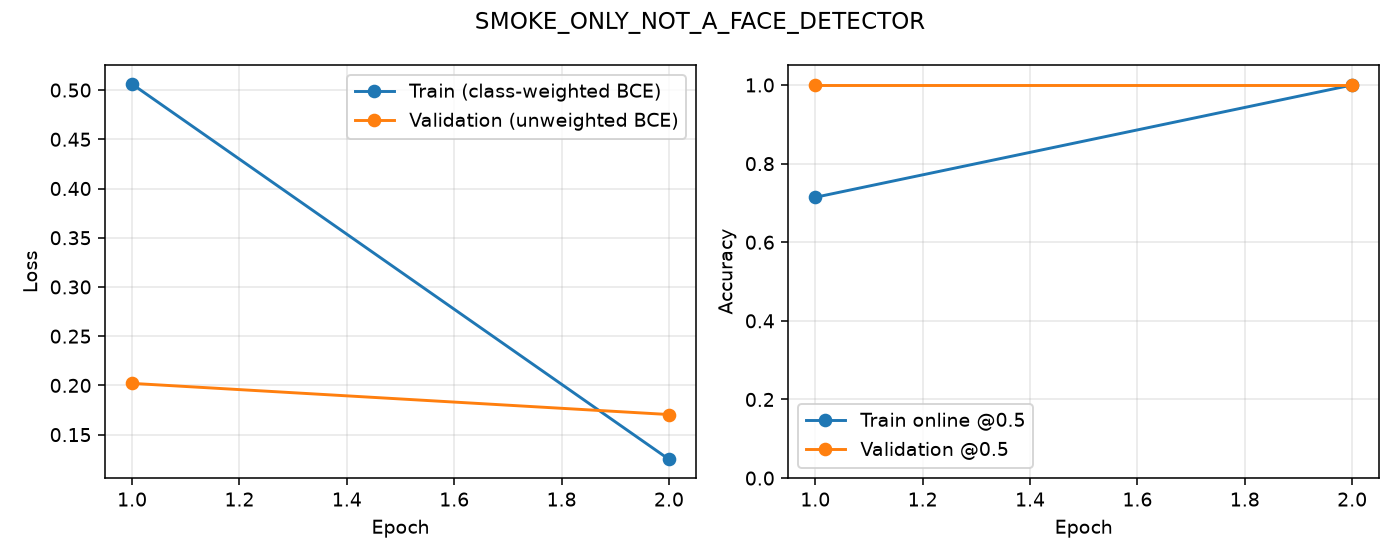

In [6]:
TRAINING_READY = False
BEST = None
CHECKPOINTS = {}
if not globals().get('DATA_READY', False):
    print('لم يبدأ التدريب: أكمل تجهيز بيانات الفئتين في المرحلة4 أولًا.')
else:
    from facejpeg.experiment import fit_jpeg_comparison
    _cached_cpu = QUICK or CPU_REAL
    CHECKPOINTS = fit_jpeg_comparison(
        PREPARED, RUN, jpeg_qualities=JPEG_TRAIN_QUALITIES, jpeg_probability=JPEG_PROBABILITY,
        epochs=EPOCHS, batch_size=BATCH_SIZE, quick=QUICK, resume=RESUME, workers=WORKERS,
        allow_cpu_real=ALLOW_CPU_REAL or CPU_REAL, cache_features=_cached_cpu,
        warmup_epochs=0 if _cached_cpu else 1, finetune_blocks=0 if _cached_cpu else 3,
        use_amp=not _cached_cpu, lr=1e-3 if _cached_cpu else 1e-4,
        use_scheduler=_cached_cpu, early_stopping_patience=8 if _cached_cpu else 5)
    assert MODEL_FOR_UI in CHECKPOINTS
    BEST = CHECKPOINTS[MODEL_FOR_UI]
    for _name in CHECKPOINTS:
        print("Training:", _name)
        display(pd.read_csv(RUN / _name / "history.csv"))
        display(DisplayImage(filename=str(RUN / _name / "learning_curves.png")))
    print("النموذجان مثبتان، ولم نفتح الاختبار بعد.")
    TRAINING_READY = True

## 7 — التحقق من إعادة التحميل قبل الاختبار
نحمّل كل best.pt مرتين ونفحص تطابق درجة صورة تحقق واحدة. هذا اختبار اتساق برمجي، وليس حساب دقة وجوه. تظهر بصمات النموذجين وحدودهما المحفوظة. لا توجد تنبؤات اختبار في هذه الخلية.

In [7]:
if not globals().get('TRAINING_READY', False):
    print('لم تكتمل المرحلة6؛ لن نحسب نتائج اختبار أو نصدر أوزانًا غير جاهزة. أكمل تدريب الوجوه أولًا.')
else:
    from facejpeg.infer import Predictor
    from facejpeg.common import read_rgb, file_sha256
    _example = PREPARED / manifest.loc[manifest.split == "val", "path"].iloc[0]
    for _name, _checkpoint in CHECKPOINTS.items():
        _first = Predictor(_checkpoint, "cpu")
        _second = Predictor(_checkpoint, "cpu")
        assert abs(_first.score(read_rgb(_example)) - _second.score(read_rgb(_example))) < 1e-7
        print(_name, "SHA256:", file_sha256(_checkpoint), "thresholds:", _first.bundle["thresholds"])
        del _first, _second
    print("نجح اختبار الحفظ وإعادة التحميل للنموذجين.")

baseline SHA256: a819d2f37e0071abc916daa0e0c99c438e5d9a2032c219178dc071878866b167 thresholds: {'low': 0.375, 'high': 0.95}
jpeg_augmented SHA256: 97a79a84b754d03d8b7e5c9c433f986cac193c5127d80e6005f0522f6fd521f5 thresholds: {'low': 0.4, 'high': 0.95}
نجح اختبار الحفظ وإعادة التحميل للنموذجين.


## 8 — اختبار النموذجين ومقارنة أثر JPEG
نتأكد من أن بصمتي النموذجين لم تتغيرا، ثم نقيّم كليهما على صور الاختبار نفسها: الأصل ثم100/90/70/50/30/10، كل نسخة مباشرة من الأصل الموحد. تُستخدم الحدود المحفوظة لكل نموذج دون تعديلها بين الجودات.

مقام الاكتشاف جميع المولّدات، والاتهام الخاطئ جميع الفوتوغرافيات، وغير الحاسم جميع الاختبار. comparison.csv وcomparison.png وCOMPARISON_AR.md تعرض A وB والفروق بالنقاط المئوية. داخل كل تجربة مصفوفات الالتباس وROC وأمثلة تغيّر الحكم إن وجدت. لا نعلن تحسنًا لمجرد ارتفاع درجة صورة، ولا نفسر QUICK كدقة وجوه. لا نعدّل التدريب بعد رؤية هذه النتائج.

19:02:11 | بدء المرحلة: تقييم الاختبار JPEG=original; total=6
Test Q=original: 100%|##########| 1/1 [00:00<00:00, 15.57batch/s]
19:02:11 | بدء المرحلة: تقييم الاختبار JPEG=100; total=6
Test Q=100: 100%|##########| 1/1 [00:00<00:00, 29.36batch/s]
19:02:11 | بدء المرحلة: تقييم الاختبار JPEG=90; total=6
Test Q=90: 100%|##########| 1/1 [00:00<00:00, 38.96batch/s]
19:02:11 | بدء المرحلة: تقييم الاختبار JPEG=70; total=6
Test Q=70: 100%|##########| 1/1 [00:00<00:00, 30.92batch/s]
19:02:11 | بدء المرحلة: تقييم الاختبار JPEG=50; total=6
Test Q=50: 100%|##########| 1/1 [00:00<00:00, 36.38batch/s]
19:02:11 | بدء المرحلة: تقييم الاختبار JPEG=30; total=6
Test Q=30: 100%|##########| 1/1 [00:00<00:00, 43.45batch/s]
19:02:11 | بدء المرحلة: تقييم الاختبار JPEG=10; total=6
Test Q=10: 100%|##########| 1/1 [00:00<00:00, 40.16batch/s]
19:02:11 | بدء المرحلة: حفظ الجداول والرسوم والتقرير; total=None
19:02:12 | اكتمل تقييم 6 صورة × 7 حالات؛ لم تُعدّل حدود التحقق
 quality  n_total  n_real  n_fake  fake_detect

,quality,n_fake,baseline_fake_detected,jpeg_augmented_fake_detected,n_real,baseline_real_falsely_accused,jpeg_augmented_real_falsely_accused,n_total,baseline_abstain_total,jpeg_augmented_abstain_total
0,original,3,3,3,3,0,0,6,1,1
1,100,3,3,3,3,0,0,6,1,1
2,90,3,2,3,3,0,0,6,2,1
3,70,3,2,3,3,0,0,6,2,1
4,50,3,2,3,3,0,0,6,2,1
5,30,3,2,3,3,0,0,6,2,1
6,10,3,0,0,3,0,0,6,4,4


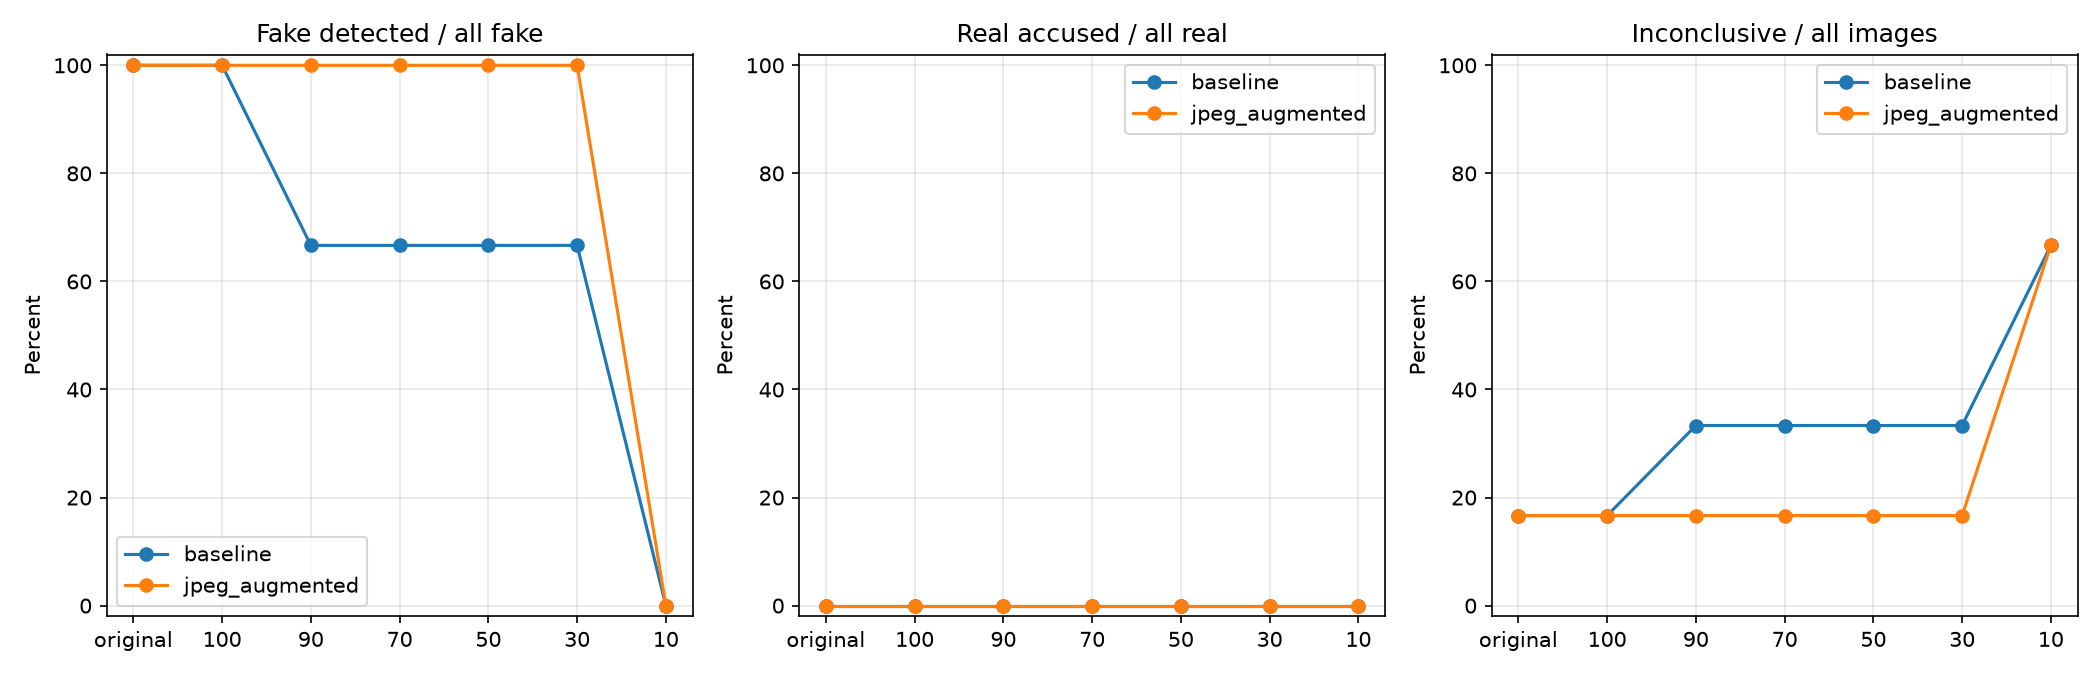

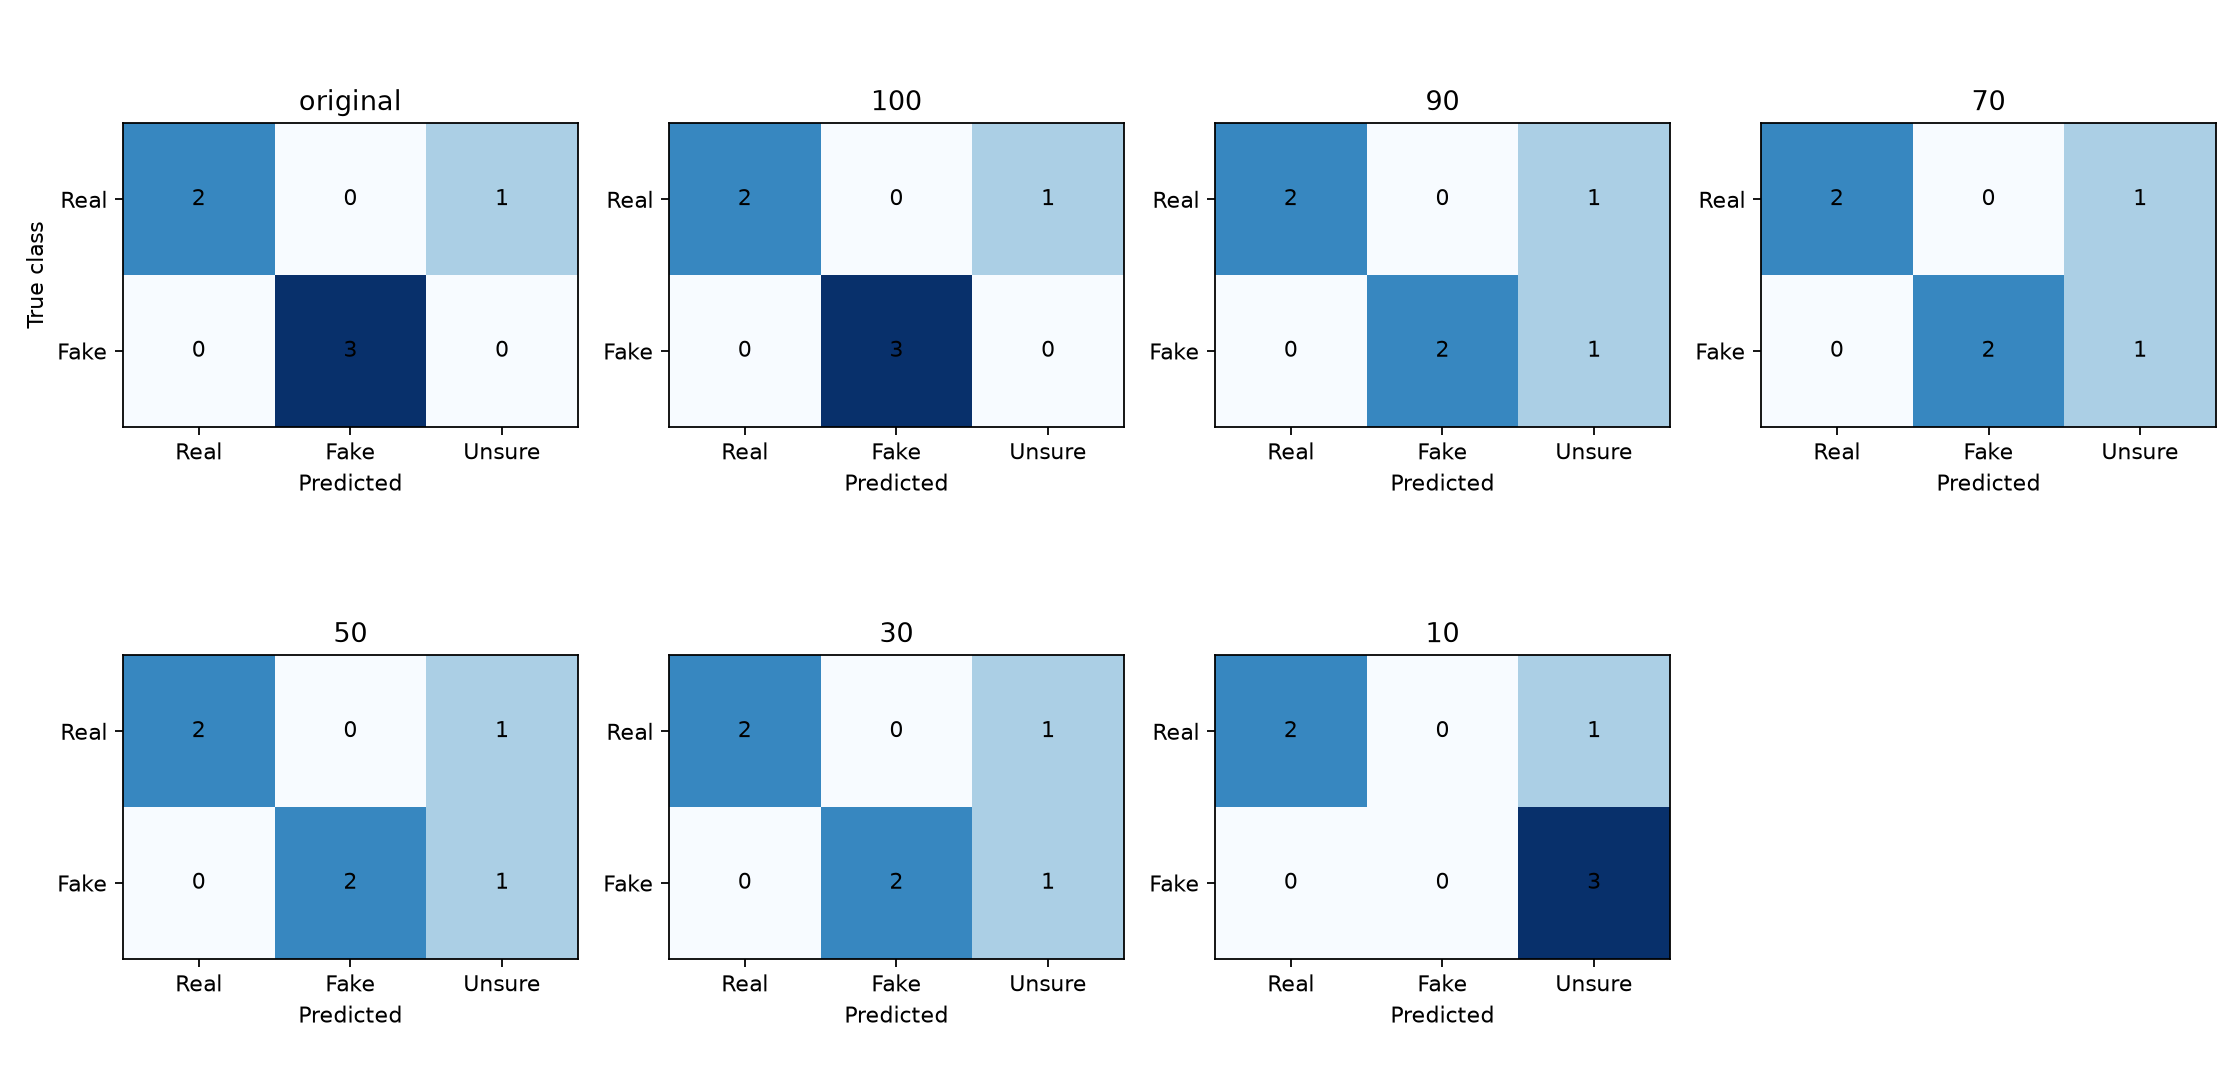

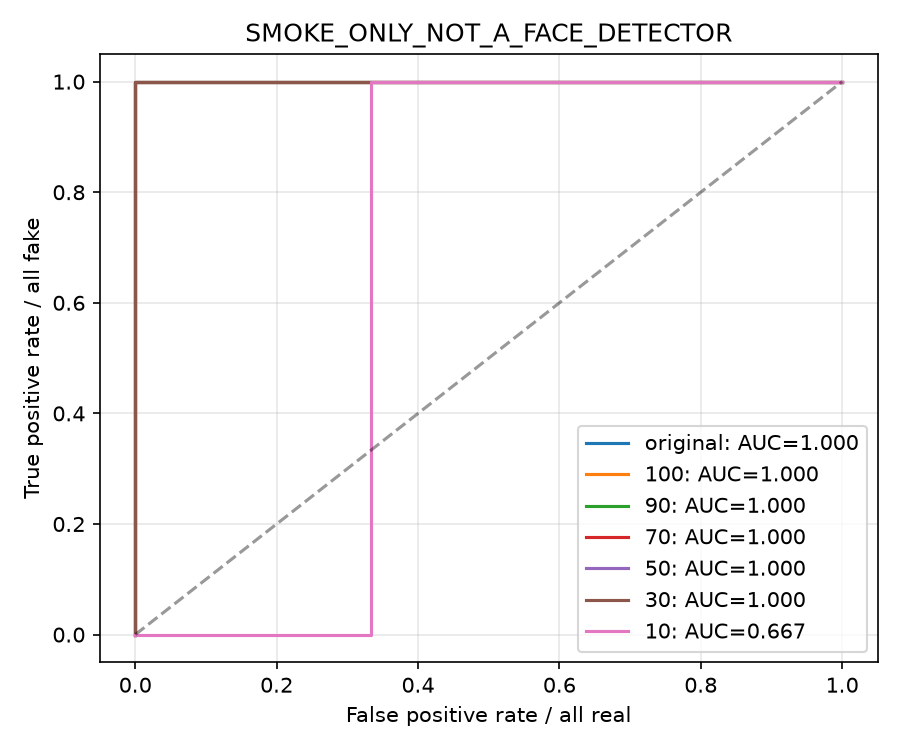

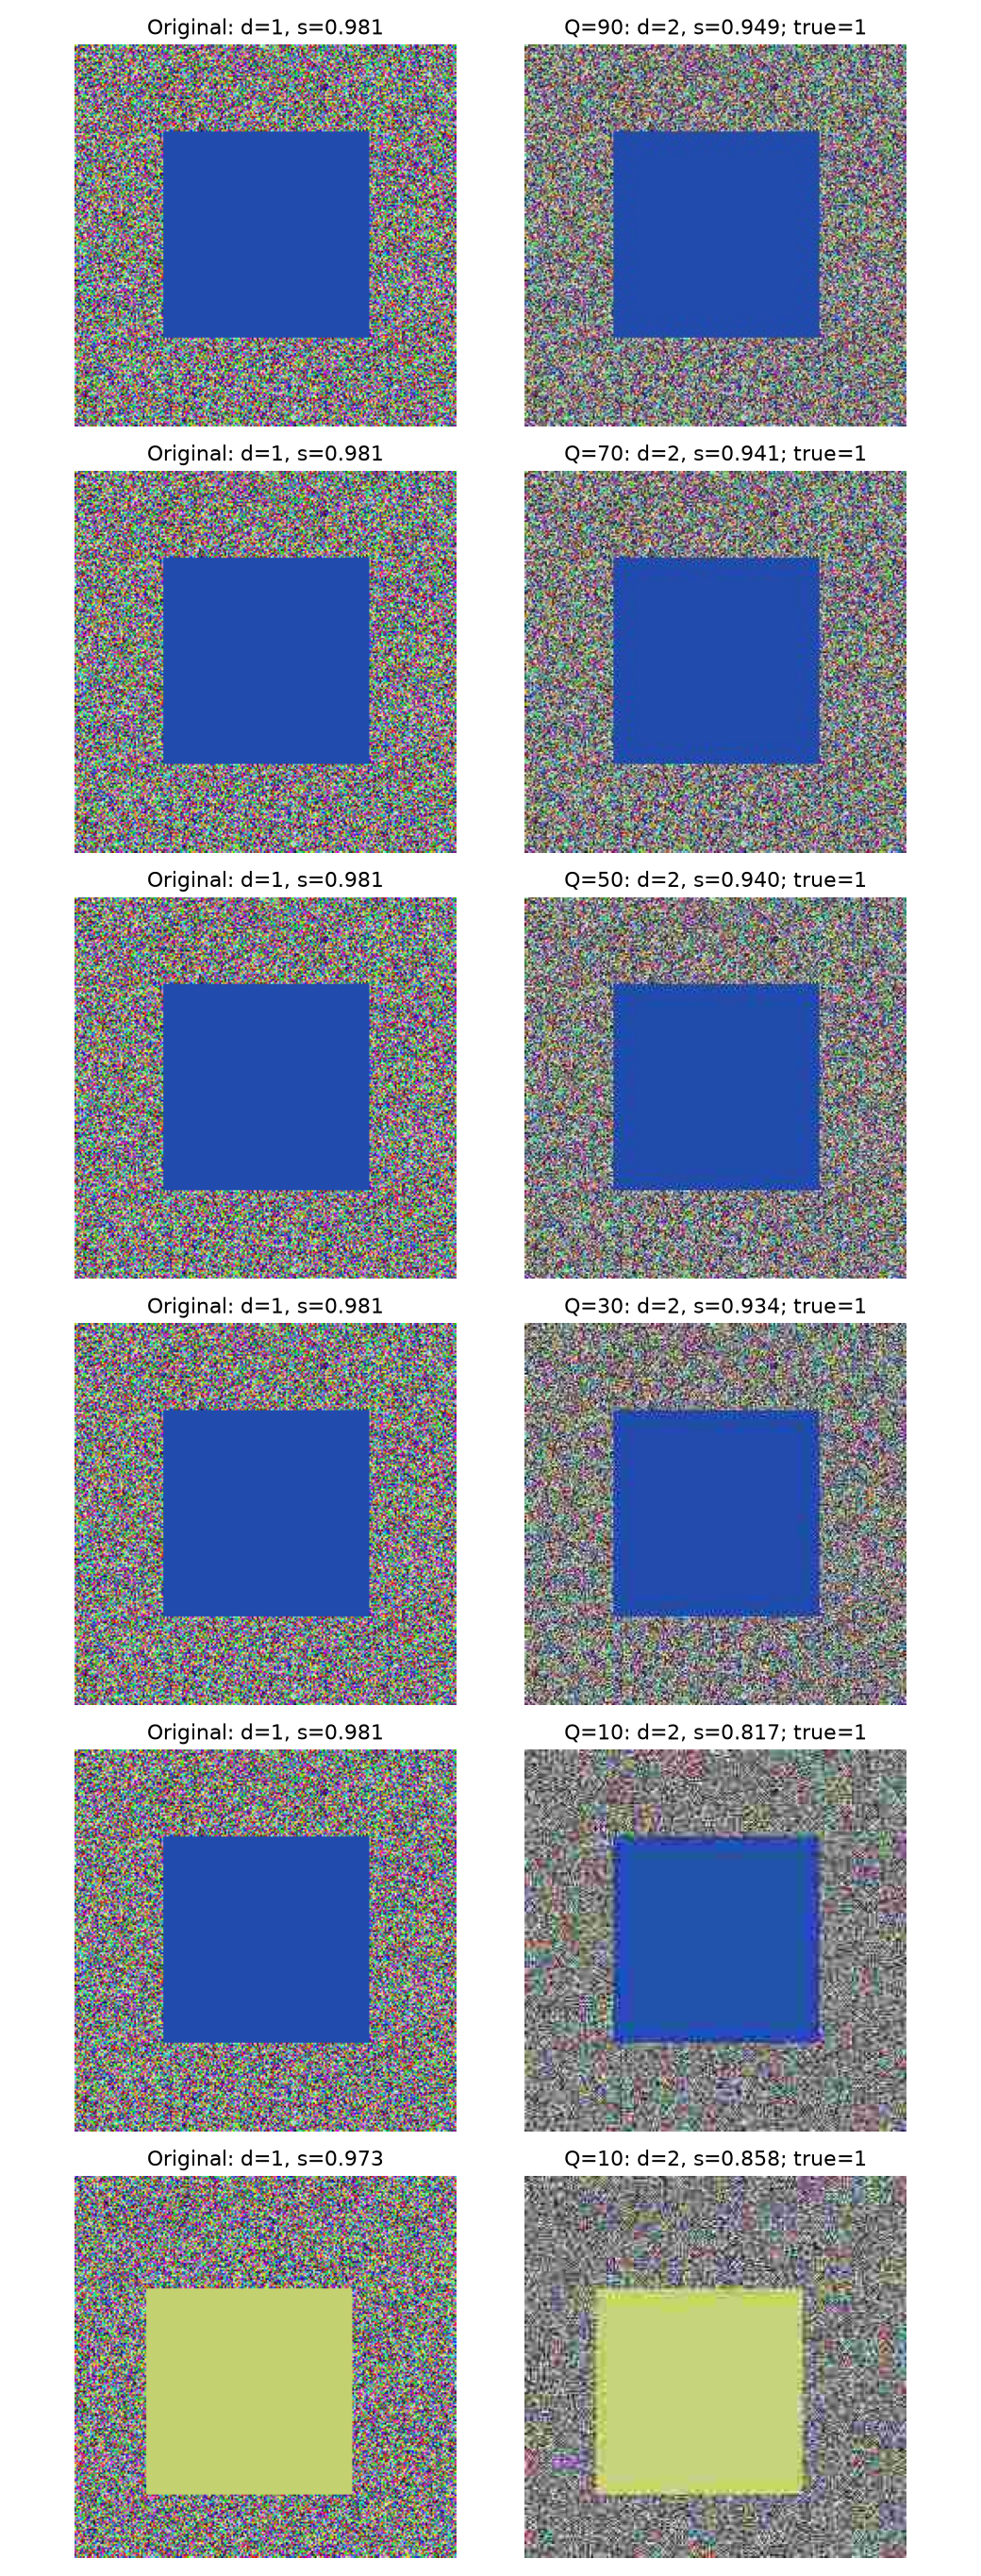

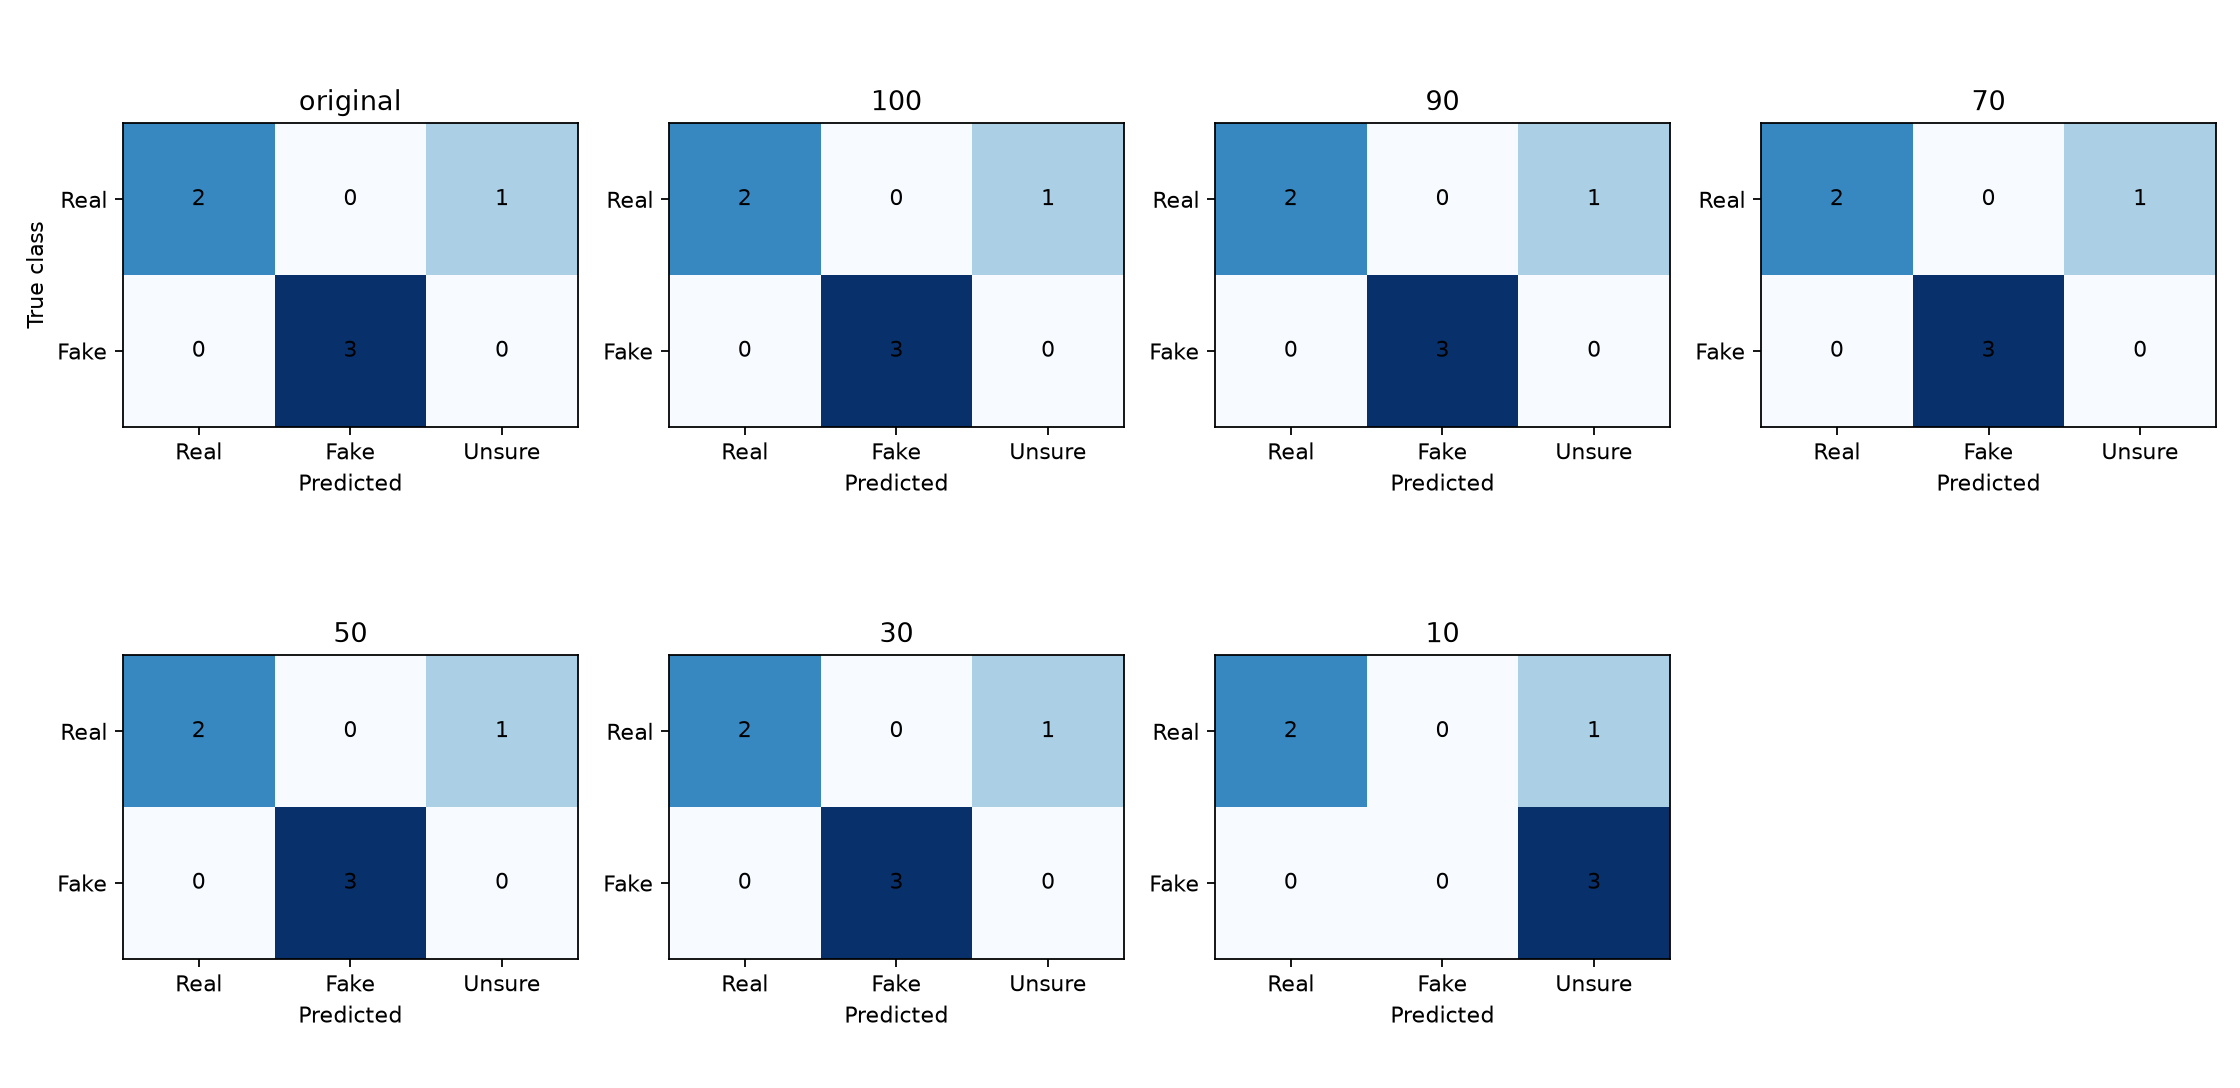

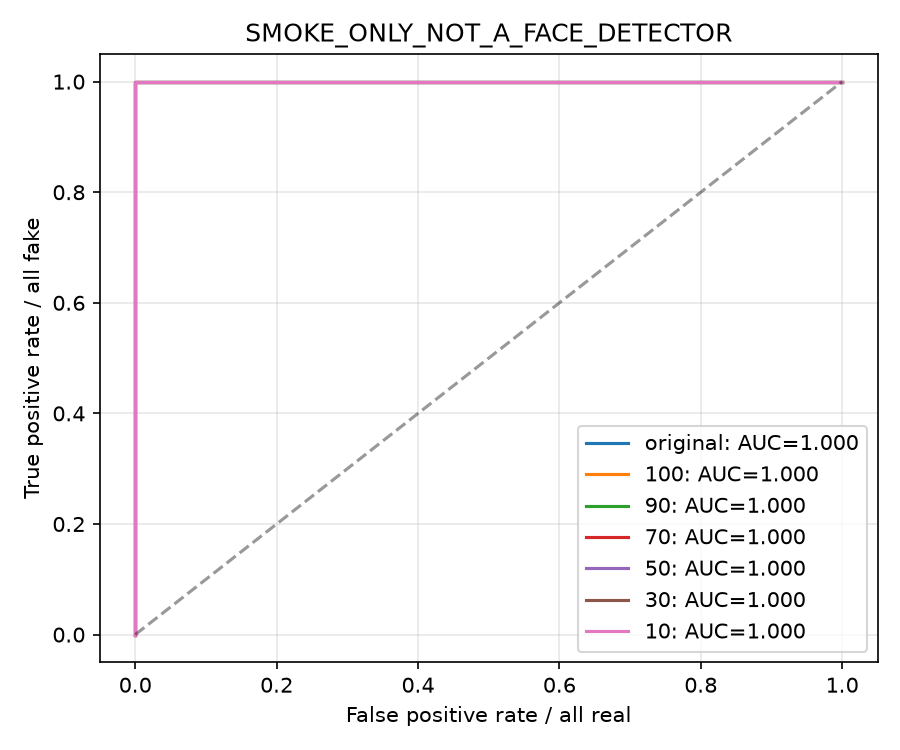

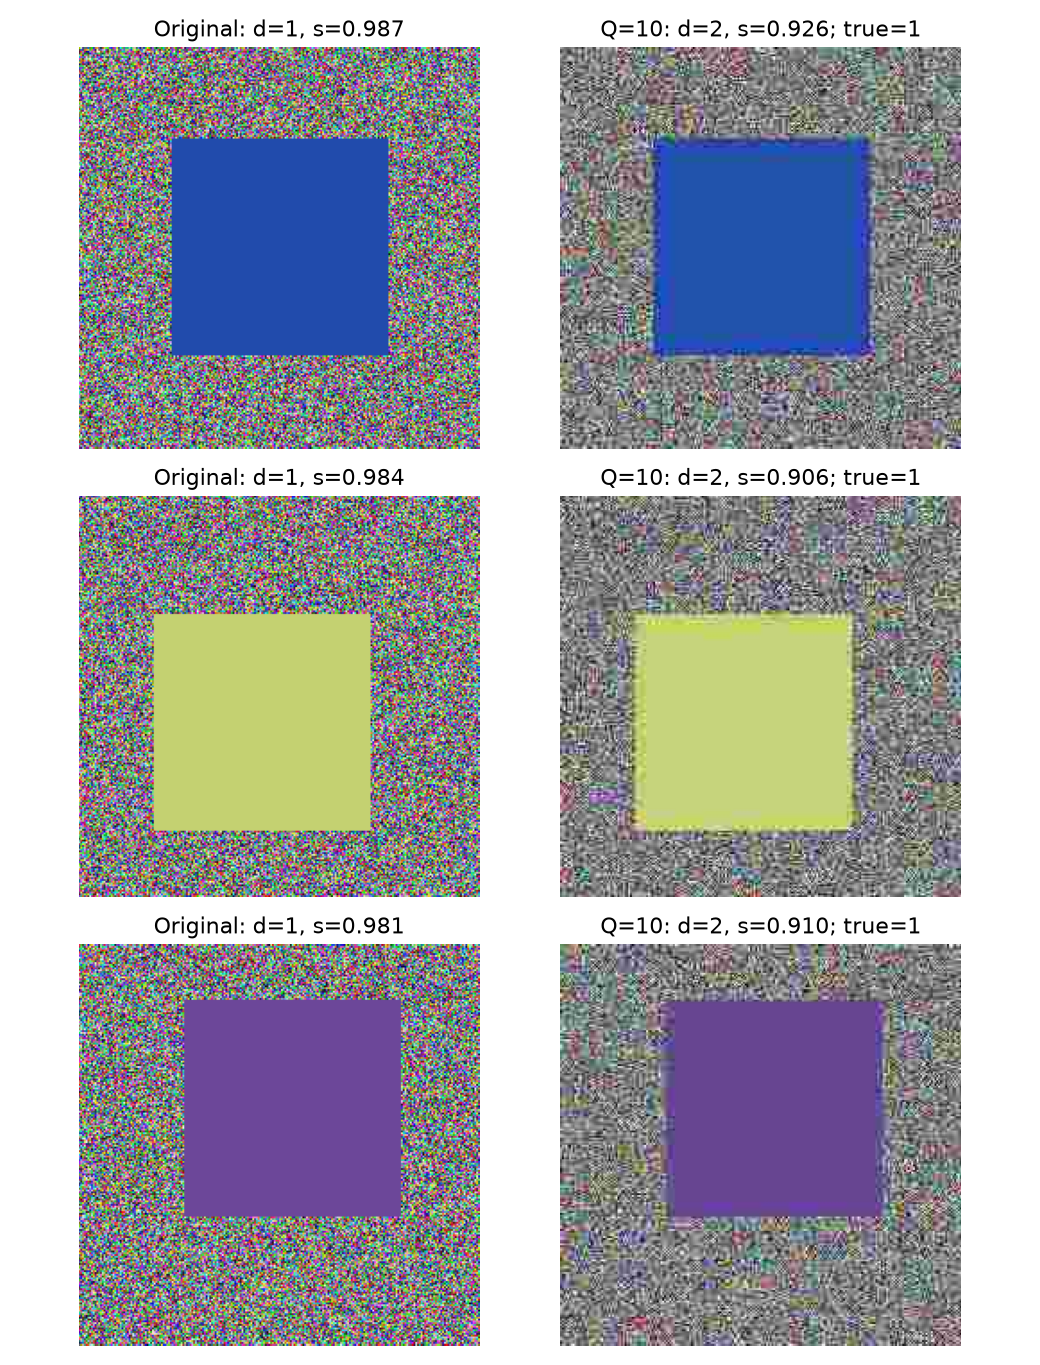

# مقارنة التدريب الأساسي والتدريب باستخدام JPEG

A: تدريب أساسي. B: ضغط JPEG عشوائي لصور التدريب فقط؛ مع التقسيم وإعدادات التدريب والبذرة نفسها.
درّبنا النموذجين واخترنا كل أفضل نموذج وحدوده من التحقق الأصلي، ثم ثبّتناهما قبل أي تنبؤ اختبار. حدود كل نموذج ثابتة عبر الجودات، وقد تختلف بين النموذجين.
كل نسخة اختبار تُنشأ مباشرة من الأصل الموحد224×224. جودة100 ليست الأصل غير المعاد ترميزه. هذه مقارنة واحدة ببذرة واحدة، ولا تثبت تفوقًا عامًا أو دلالة إحصائية.

**اختبار برمجيات على أشكال هندسية فقط؛ ليست نتائج كشف وجوه ولا قياسًا لتحسن دقتها.**

- الجودة original: اكتشاف المولّد A=3/3 وB=3/3؛ الاتهام الخاطئ A=0/3 وB=0/3؛ غير الحاسم A=1/6 وB=1/6. فرق B−A في الاكتشاف +0.0 نقطة مئوية، وفي الاتهام الخاطئ +0.0 نقطة.
- الجودة 100: اكتشاف المولّد A=3/3 وB=3/3؛ الاتهام الخاطئ A=0/3 وB=0/3؛ غير الحاسم A=1/6 وB=1/6. فرق B−A في الاكتشاف +0.0 نقطة مئوية، وفي الاتهام الخاطئ +0.0 نقطة.
- الجودة 90: اكتشاف المولّد A=2/3 وB=3/3؛ الاتهام الخاطئ A=0/3 وB=0/3؛ غير الحاسم A=2/6 وB=1/6. فرق B−A في الاكتشاف +33.3 نقطة مئوية، وفي الاتهام الخاطئ +0.0 نقطة.
- الجودة 70: اكتشاف المولّد A=2/3 وB=3/3؛ الاتهام الخاطئ A=0/3 وB=0/3؛ غير الحاسم A=2/6 وB=1/6. فرق B−A في الاكتشاف +33.3 نقطة مئوية، وفي الاتهام الخاطئ +0.0 نقطة.
- الجودة 50: اكتشاف المولّد A=2/3 وB=3/3؛ الاتهام الخاطئ A=0/3 وB=0/3؛ غير الحاسم A=2/6 وB=1/6. فرق B−A في الاكتشاف +33.3 نقطة مئوية، وفي الاتهام الخاطئ +0.0 نقطة.
- الجودة 30: اكتشاف المولّد A=2/3 وB=3/3؛ الاتهام الخاطئ A=0/3 وB=0/3؛ غير الحاسم A=2/6 وB=1/6. فرق B−A في الاكتشاف +33.3 نقطة مئوية، وفي الاتهام الخاطئ +0.0 نقطة.
- الجودة 10: اكتشاف المولّد A=0/3 وB=0/3؛ الاتهام الخاطئ A=0/3 وB=0/3؛ غير الحاسم A=4/6 وB=4/6. فرق B−A في الاكتشاف +0.0 نقطة مئوية، وفي الاتهام الخاطئ +0.0 نقطة.

ارتفاع الاكتشاف مفيد، وارتفاع الاتهام الخاطئ غير مرغوب. قد يزيد غير الحاسم أو ينقص؛ لا نعلن التحسن من رقم منفرد. النسب مقامها جميع صور الفئة أو جميع الاختبار، وليست الحالات المحسومة فقط.
لا نعدّل الإعدادات بناءً على هذا الاختبار. تطوير تجربة لاحقة يحتاج تحققًا مستقلًا، واختبارًا نهائيًا لم يُستخدم لاختيار الإعدادات.


In [8]:
if not globals().get('TRAINING_READY', False):
    print('لم تكتمل المرحلة6؛ لن نحسب نتائج اختبار أو نصدر أوزانًا غير جاهزة. أكمل تدريب الوجوه أولًا.')
else:
    from facejpeg.experiment import evaluate_jpeg_comparison
    table = evaluate_jpeg_comparison(PREPARED, RUN, device="cpu" if QUICK or CPU_REAL else None)
    display(table[["quality", "n_fake", "baseline_fake_detected", "jpeg_augmented_fake_detected",
                   "n_real", "baseline_real_falsely_accused", "jpeg_augmented_real_falsely_accused",
                   "n_total", "baseline_abstain_total", "jpeg_augmented_abstain_total"]])
    display(DisplayImage(filename=str(RUN / "comparison.png")))
    for _name in CHECKPOINTS:
        for _figure in ["confusion_matrices.png", "roc_curves.png", "changed_examples.png"]:
            _path = RUN / _name / "evaluation" / _figure
            if _path.exists():
                print(_name, _figure)
                display(DisplayImage(filename=str(_path)))
    display(Markdown((RUN / "COMPARISON_AR.md").read_text()))

## 9 — حفظ النموذجين والتقارير وتنزيل ZIP النتائج
يتضمن ZIP أفضل وlast.pt لكل نموذج والخطة والبصمات والتقارير وmanifest. يستبعد ميزات CPU القابلة لإعادة الحساب، وصور prepared افتراضيًا لتقليل زمن الضغط. لاستكمال التدريب احتفظ بمجلد RUN كاملًا على Drive، أو فعّل EXPORT_INCLUDE_PREPARED=True للاحتفاظ بصور الاستكمال في ZIP.

بعد اكتمال الخلية نزّل ZIP من لوحة Files في Colab؛ لا يُنزَّل تلقائيًا. للتنبؤ لاحقًا استخدم best.pt من تجربة وجوه فعلية (داخل baseline أو jpeg_augmented)، واحتفظ بمعالجة الصورة والحدود المحفوظة. حفظ الدفتر وحده لا يحفظ الأوزان.

In [9]:
if not globals().get('TRAINING_READY', False):
    print('لم تكتمل المرحلة6؛ لن نحسب نتائج اختبار أو نصدر أوزانًا غير جاهزة. أكمل تدريب الوجوه أولًا.')
else:
    import zipfile
    RESULT_ZIP = PROJECT / (EXPERIMENT + "_results.zip")
    _export_files = [p for p in RUN.rglob("*") if p.is_file() and "feature_cache" not in p.relative_to(RUN).parts and (EXPORT_INCLUDE_PREPARED or not p.is_relative_to(PREPARED / "images"))]
    from tqdm.auto import tqdm
    with zipfile.ZipFile(RESULT_ZIP, "w", zipfile.ZIP_DEFLATED) as _zip:
        for _p in tqdm(_export_files, desc="Export results", unit="file"):
            _zip.write(_p, _p.relative_to(RUN))
    print("Results ZIP:", RESULT_ZIP)
    print("Best checkpoint:", BEST)
    print("Resume images included:", EXPORT_INCLUDE_PREPARED)

Export results: 100%|##########| 67/67 [00:01<00:00, 49.41file/s]
Results ZIP: /workspace/Final-Projects/facejpeg_final_v2_3_1/jpeg_quick_v2_3_1_results.zip
Best checkpoint: /workspace/Final-Projects/facejpeg_final_v2_3_1/runs/jpeg_quick_v2_3_1/jpeg_augmented/best.pt
Resume images included: False


## 10 — فتح الواجهة بعد التحقق من أوزان الوجوه
تُفتح الواجهة بعد اكتمال المرحلة6 فقط. يفحص الدفتر ملف best.pt فعليًا، ويرفض الأوزان الهندسية أو الأوزان التالفة بدل استخدامها لكشف الوجوه. عند تغيير الإعدادات في المرحلة3 تُغلق الواجهة القديمة ويُلغى اختيار النموذج السابق. لذلك لا يعيد خطأ التنزيل فتح نموذج QUICK قديم.

بعد التدريب ارفع JPG/PNG لوجه أمامي واحد واضح، واختر جودة JPEG. كل صورة جديدة تحتاج زر التحليل فقط. الرابط مؤقت مع جلسة Colab. للاستعمال لاحقًا احتفظ بـbest.pt وافتح دفتر التنبؤ فقط. في دفتر اختبار البرمجيات المنفصل يسمح بعرض JPEG دون أحكام أصالة، وموسوم بذلك بوضوح.

In [10]:
import pickle
from facejpeg.infer import Predictor
from app import create_app
if globals().get("demo") is not None:
    demo.close()
def _verified_interface():
    if not globals().get("TRAINING_READY", False) or not globals().get("BEST"):
        print("الواجهة غير جاهزة للكشف: أكمل تجهيز البيانات في4 والتدريب في6. لم نحمّل أوزان QUICK بدلًا من نموذج الوجوه.")
        return None
    try:
        _checked = Predictor(BEST, "cpu")
        _faces_enabled = _checked.face_classification_enabled
        del _checked
    except (ValueError, OSError, RuntimeError, EOFError, KeyError, TypeError, pickle.UnpicklingError):
        print("تعذر تحميل best.pt صالح. أعد تحميل أوزان تجربة الوجوه السليمة أو أكمل المرحلة6.")
        return None
    if not _faces_enabled and not ALLOW_SOFTWARE_PREVIEW:
        print("رُفض فتح الواجهة بأوزان هندسية: اختر best.pt من تدريب REAL_CPU على بيانات وجوه فعلية. تغيير اسم الملف لا يكفي.")
        return None
    if not LAUNCH_UI:
        print("تشغيل الواجهة معطّل للفحص غير التفاعلي؛ اجعل LAUNCH_UI=True عند الحاجة.")
        return None
    return create_app(BEST)
demo = _verified_interface()
if demo is not None:
    demo.launch(share=SHARE_GRADIO if IN_COLAB else False, debug=False)


تشغيل الواجهة معطّل للفحص غير التفاعلي؛ اجعل LAUNCH_UI=True عند الحاجة.
